In [1]:
import os
import torch
import numpy as np
import pandas as pd
from PIL import Image

from sklearn.utils.class_weight import compute_class_weight

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms

In [2]:
train_df = pd.read_csv("train/_classes.csv")
valid_df = pd.read_csv("valid/_classes.csv")
test_df = pd.read_csv("test/_classes.csv")

In [3]:
train_df["split"] = "train"
valid_df["split"] = "valid"
test_df["split"] = "test"

In [4]:
label_columns = train_df.columns[1:-1]

train_df["label"] = train_df[label_columns].idxmax(axis=1)
valid_df["label"] = valid_df[label_columns].idxmax(axis=1)
test_df["label"] = test_df[label_columns].idxmax(axis=1)

In [5]:
classes = sorted(train_df["label"].unique())

class_to_idx = {
    cls: idx
    for idx, cls in enumerate(classes)
}

idx_to_class = {
    idx: cls
    for cls, idx in class_to_idx.items()
}

print(class_to_idx)

{' anold-chiari-malformation': 0, ' arachnoid-cyst': 1, ' cerebellah-hypoplasia': 2, ' colphocephaly': 3, ' encephalocele': 4, ' holoprosencephaly': 5, ' hydracenphaly': 6, ' intracranial-hemorrdge': 7, ' intracranial-tumor': 8, ' m-magna': 9, ' mild-ventriculomegaly': 10, ' moderate-ventriculomegaly': 11, ' normal': 12, ' polencephaly': 13, ' severe-ventriculomegaly': 14, ' vein-of-galen': 15}


In [6]:
train_df["target"] = train_df["label"].map(class_to_idx)
valid_df["target"] = valid_df["label"].map(class_to_idx)
test_df["target"] = test_df["label"].map(class_to_idx)

In [7]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )

])

In [9]:
class FetalDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        img_path = os.path.join(

            row["split"],

            row["filename"]

        )

        image = Image.open(img_path).convert("RGB")

        if self.transform:

            image = self.transform(image)

        label = row["target"]

        return image, label

In [10]:
train_dataset = FetalDataset(

    train_df,

    train_transform

)

valid_dataset = FetalDataset(

    valid_df,

    test_transform

)

test_dataset = FetalDataset(

    test_df,

    test_transform

)

In [11]:
class_weights = compute_class_weight(

    class_weight="balanced",

    classes=np.unique(train_df["target"]),

    y=train_df["target"]

)

class_weights = torch.tensor(

    class_weights,

    dtype=torch.float

)

print(class_weights)

tensor([ 2.0142,  0.7913,  0.8604,  1.2309,  0.7843, 12.6607,  5.2132,  2.0610,
         6.3304,  2.7695,  0.4545,  0.3435,  0.3904,  1.0678,  0.9428, 22.1562])


In [12]:
train_loader = DataLoader(

    train_dataset,

    batch_size=16,

    shuffle=True,

    num_workers=0

)

valid_loader = DataLoader(

    valid_dataset,

    batch_size=16,

    shuffle=False,

    num_workers=0

)

test_loader = DataLoader(

    test_dataset,

    batch_size=16,

    shuffle=False,

    num_workers=0

)

In [13]:
print("Training Images :", len(train_dataset))

print("Validation Images :", len(valid_dataset))

print("Testing Images :", len(test_dataset))

Training Images : 1418
Validation Images : 174
Testing Images : 176


In [14]:
images, labels = next(iter(train_loader))

print(images.shape)

print(labels.shape)

torch.Size([16, 3, 224, 224])
torch.Size([16])


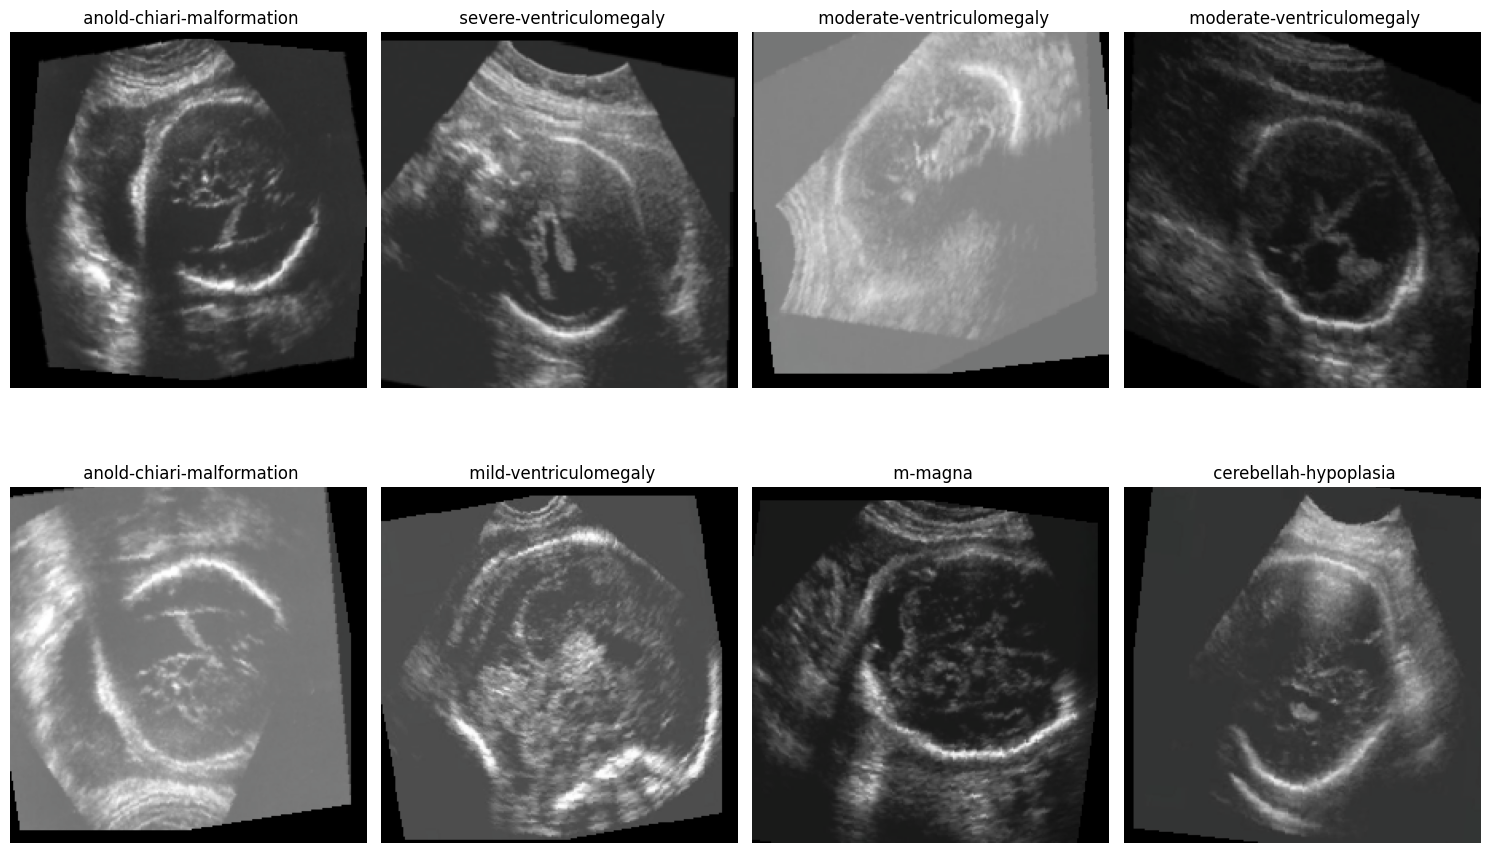

In [15]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

plt.figure(figsize=(15,10))

for i in range(8):

    plt.subplot(2,4,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(idx_to_class[labels[i].item()])

    plt.axis("off")

plt.tight_layout()

plt.show()

In [16]:
import json

with open("class_mapping.json","w") as f:

    json.dump(class_to_idx,f)

print("Class Mapping Saved")

Class Mapping Saved


In [17]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [18]:
print(class_weights)

tensor([ 2.0142,  0.7913,  0.8604,  1.2309,  0.7843, 12.6607,  5.2132,  2.0610,
         6.3304,  2.7695,  0.4545,  0.3435,  0.3904,  1.0678,  0.9428, 22.1562])


In [19]:
for cls, weight in zip(classes, class_weights):

    print(f"{cls:<30} {weight:.3f}")

 anold-chiari-malformation     2.014
 arachnoid-cyst                0.791
 cerebellah-hypoplasia         0.860
 colphocephaly                 1.231
 encephalocele                 0.784
 holoprosencephaly             12.661
 hydracenphaly                 5.213
 intracranial-hemorrdge        2.061
 intracranial-tumor            6.330
 m-magna                       2.770
 mild-ventriculomegaly         0.454
 moderate-ventriculomegaly     0.344
 normal                        0.390
 polencephaly                  1.068
 severe-ventriculomegaly       0.943
 vein-of-galen                 22.156


In [20]:
images, labels = next(iter(train_loader))

print("Images")

print(images.shape)

print()

print("Labels")

print(labels)

Images
torch.Size([16, 3, 224, 224])

Labels
tensor([10, 11,  1, 13, 15, 13, 12,  1,  3,  2, 12,  1, 12,  3,  2, 13])


In [21]:
print(images.min())

print(images.max())

tensor(-2.1179)
tensor(2.6400)


In [22]:
dataset_info = {

    "Train Images": len(train_dataset),

    "Validation Images": len(valid_dataset),

    "Test Images": len(test_dataset),

    "Classes": len(classes),

    "Batch Size":16,

    "Image Size":"224x224"

}

import json

with open("dataset_info.json","w") as f:

    json.dump(dataset_info,f,indent=4)